# Assignment 1: Analyzing Sales Data from Multiple File Formats

In [8]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Creating sample datasets in different formats
csv_data = {
    'Transaction_ID': [101, 102, 103, 104, 105, 105],
    'Product': ['Laptop', 'Mouse', 'Monitor', 'Keyboard', 'Laptop', 'Laptop'],
    'Price': [1200, 25, 300, 80, 1200, 1200],
    'Quantity': [1, 2, np.nan, 1, 1, 1],
    'Date': ['2023-10-01', '2023-10-01', '2023-10-02', '2023-10-03', '2023-10-04', '2023-10-04']
}
pd.DataFrame(csv_data).to_csv('sales_data.csv', index=False)

excel_data = {
    'Transaction_ID': [106, 107, 108],
    'Product': ['mouse', 'Tablet', 'Monitor'],
    'Price': [25, 450, 300],
    'Quantity': [5, 1, 2],
    'Date': ['2023-10-05', '2023-10-06', '2023-10-07']
}
pd.DataFrame(excel_data).to_excel('sales_data.xlsx', index=False)

json_data = [
    {'Transaction_ID': 109, 'Product': 'Keyboard', 'Price': 80, 'Quantity': 3, 'Date': '2023-10-08'},
    {'Transaction_ID': 110, 'Product': 'Laptop', 'Price': 1200, 'Quantity': 1, 'Date': '2023-10-09'}
]

with open('sales_data.json', 'w') as f:
    json.dump(json_data, f)

print("Sample files generated successfully!")

Sample files generated successfully!


In [9]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Steps 1 & 2: Load and Explore the Datasets

In [10]:
df_csv = pd.read_csv('sales_data.csv')
df_excel = pd.read_excel('sales_data.xlsx')
df_json = pd.read_json('sales_data.json')

print("--- CSV Data Summary ---")
df_csv.info()

print("\n--- Excel Data Summary ---")
df_excel.info()

print("\n--- JSON Data Summary ---")
df_json.info()

--- CSV Data Summary ---
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Transaction_ID  6 non-null      int64  
 1   Product         6 non-null      str    
 2   Price           6 non-null      int64  
 3   Quantity        5 non-null      float64
 4   Date            6 non-null      str    
dtypes: float64(1), int64(2), str(2)
memory usage: 470.0 bytes

--- Excel Data Summary ---
<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Transaction_ID  3 non-null      int64
 1   Product         3 non-null      str  
 2   Price           3 non-null      int64
 3   Quantity        3 non-null      int64
 4   Date            3 non-null      str  
dtypes: int64(3), str(2)
memory usage: 300.0 bytes

--- JSON Data Summary ---
<class 'pand

## Steps 3, 4, & 5: Data Cleaning, Transformation, and Consolidation

In [11]:
# Combine all datasets
df_raw = pd.concat([df_csv, df_excel, df_json], ignore_index=True)

# Remove duplicate rows
df_cleaned = df_raw.drop_duplicates()

# Handle missing values by filling with standard defaults
df_cleaned['Quantity'] = df_cleaned['Quantity'].fillna(1)

# Standardize text capitalization (e.g. mouse -> Mouse)
df_cleaned['Product'] = df_cleaned['Product'].str.capitalize()

# Derive a new variable (Total Revenue)
df_cleaned['Total_Revenue'] = df_cleaned['Price'] * df_cleaned['Quantity']

# Ensure correct datatypes
df_cleaned['Date'] = pd.to_datetime(df_cleaned['Date'])

display(df_cleaned)

,Transaction_ID,Product,Price,Quantity,Date,Total_Revenue
0,101,Laptop,1200,1.0,2023-10-01,1200.0
1,102,Mouse,25,2.0,2023-10-01,50.0
2,103,Monitor,300,1.0,2023-10-02,300.0
3,104,Keyboard,80,1.0,2023-10-03,80.0
4,105,Laptop,1200,1.0,2023-10-04,1200.0
6,106,Mouse,25,5.0,2023-10-05,125.0
7,107,Tablet,450,1.0,2023-10-06,450.0
8,108,Monitor,300,2.0,2023-10-07,600.0
9,109,Keyboard,80,3.0,2023-10-08,240.0
10,110,Laptop,1200,1.0,2023-10-09,1200.0


## Step 6: Descriptive Statistics and Metrics

In [12]:
total_sales = df_cleaned['Total_Revenue'].sum()
avg_order_value = df_cleaned['Total_Revenue'].mean()
product_sales = df_cleaned.groupby('Product')['Total_Revenue'].sum().reset_index()

print(f"Total Revenue Generated: ${total_sales:,.2f}")
print(f"Average Order Value: ${avg_order_value:,.2f}\n")
print("Sales performance by Product Category:")
display(product_sales)

Total Revenue Generated: $5,445.00
Average Order Value: $544.50

Sales performance by Product Category:


,Product,Total_Revenue
0,Keyboard,320.0
1,Laptop,3600.0
2,Monitor,900.0
3,Mouse,175.0
4,Tablet,450.0


## Step 7: Visualizations

C:\Users\anjal\AppData\Local\Temp\ipykernel_8616\393325774.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=product_sales, x='Product', y='Total_Revenue', palette='viridis')


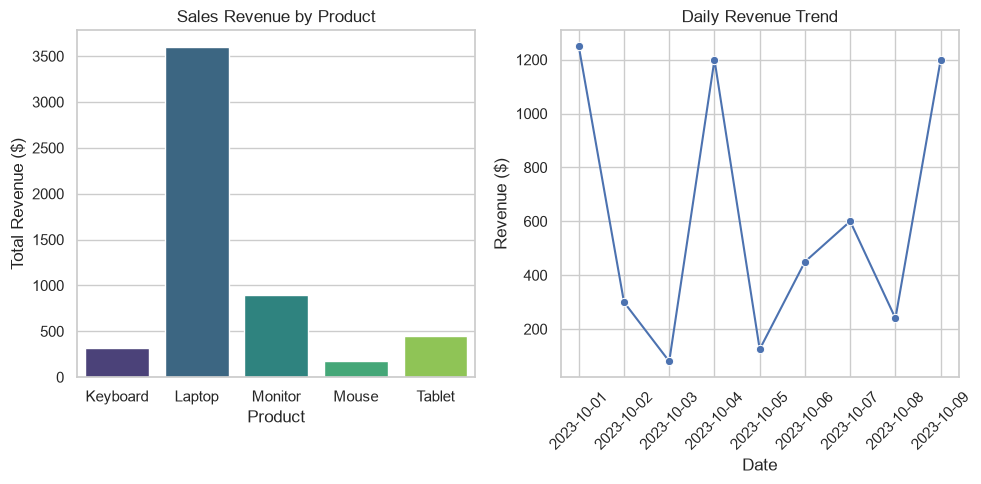

In [13]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Subplot 1: Sales Distribution by Product
plt.subplot(1, 2, 1)
sns.barplot(data=product_sales, x='Product', y='Total_Revenue', palette='viridis')
plt.title('Sales Revenue by Product')
plt.xlabel('Product')
plt.ylabel('Total Revenue ($)')

# Subplot 2: Revenue Trend Over Time
plt.subplot(1, 2, 2)
trend_df = df_cleaned.groupby('Date')['Total_Revenue'].sum().reset_index()
sns.lineplot(data=trend_df, x='Date', y='Total_Revenue', marker='o', color='b')
plt.title('Daily Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()